In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from bayes import BetaBernoulli, thompson_sampling_bandit, demonstrate_conjugate_update

In [2]:
demonstrate_conjugate_update()

=== Conjugate Prior Worked Example ===
Prior: Beta(α=1.0, β=1.0) | mean=0.500
After 7 successes + 3 failures: Beta(α=8.0, β=4.0) | mean=0.667
Expected: Beta(8, 4), mean ≈ 0.667
Match: True


In [3]:
# 2-arm bandit: Arm 0 has true p=0.4, Arm 1 has true p=0.7
true_probs = [0.4, 0.7]
actions, rewards, posteriors = thompson_sampling_bandit(true_probs, num_rounds=1000)

print("\n=== Final Posteriors ===")
for i, post in enumerate(posteriors):
    print(f"Arm {i}: {post}  (true p = {true_probs[i]})")

print(f"\nTotal reward: {sum(rewards)}")
print(f"Average reward: {np.mean(rewards):.3f}")


=== Final Posteriors ===
Arm 0: Beta(α=1.0, β=6.0) | mean=0.143  (true p = 0.4)
Arm 1: Beta(α=715.0, β=282.0) | mean=0.717  (true p = 0.7)

Total reward: 714
Average reward: 0.714


Arm selection counts: {0: 5, 1: 995}


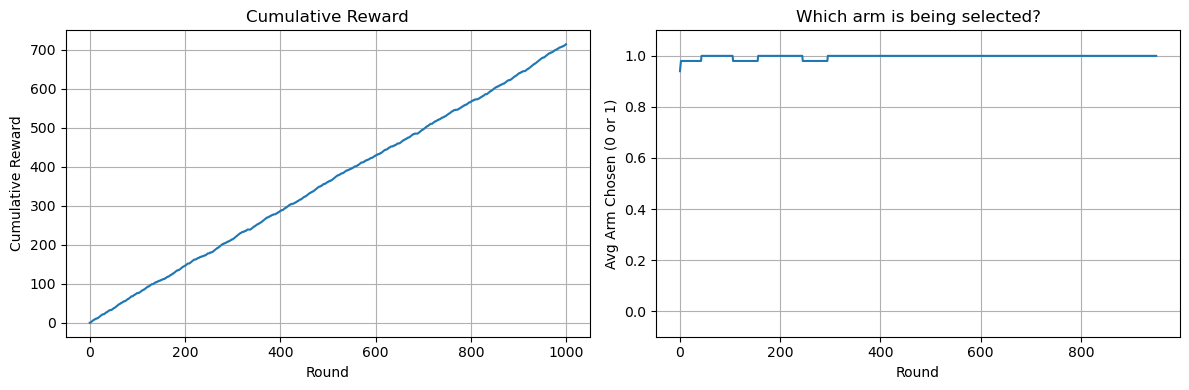

In [4]:

from collections import Counter
counts = Counter(actions)
print("Arm selection counts:", dict(counts))

# Plot: cumulative reward + arm choices
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
cumulative = np.cumsum(rewards)
plt.plot(cumulative)
plt.xlabel("Round")
plt.ylabel("Cumulative Reward")
plt.title("Cumulative Reward")
plt.grid(True)

plt.subplot(1, 2, 2)
# Moving average of chosen arm
window = 50
arm_series = np.array(actions)
moving = np.convolve(arm_series, np.ones(window)/window, mode='valid')
plt.plot(moving)
plt.xlabel("Round")
plt.ylabel("Avg Arm Chosen (0 or 1)")
plt.title("Which arm is being selected?")
plt.ylim(-0.1, 1.1)
plt.grid(True)

plt.tight_layout()
plt.show()